# Experimenting
---
This file is for keeping track of all the variations I perform for reproducability's sake

#### Ideas

- It would be cool to recreate the sinograms from "Optical Tomography in Medical Imaging"
- Also an animated plot of sequentially lighting up each source individually
 

In [5]:
# Load dependencies
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.tri import Triangulation
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

import optical_tomography.model_region as mr
from optical_tomography.mesh_creation import CircularMesh, plot_function_on_mesh
from optical_tomography.forward import optical_tomography_forward, generate_equidistant_sources

%cd /home/maxdo/GRA/Optical-Tomography/

/home/maxdo/GRA/Optical-Tomography


### Baseline

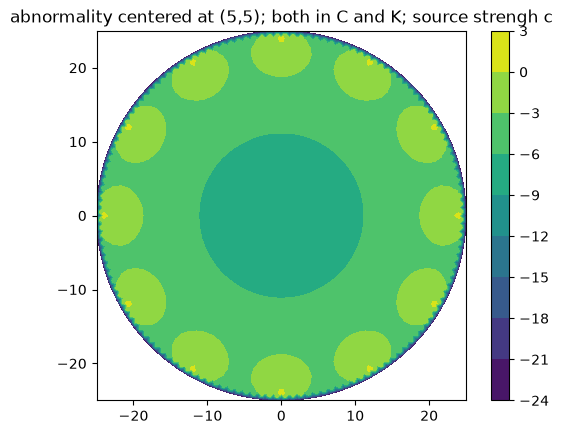

In [4]:
mesh = CircularMesh(25, (0,0), 25)
sources = generate_equidistant_sources(radius=mesh.radius - 0.75*(mesh.radius / mesh.n_rings),
                                       n = 12,
                                       values=np.repeat(mr.c, 12))
Phi = optical_tomography_forward(mesh=mesh,
                                 absorption=mr.get_absorption,
                                 diffusion=mr.get_diffusion,
                                 sources=sources)
mr.plot_function_on_R(mr.get_absorption, -40, 40, -40, 40, "images/test_phi/baseline/absorption_region.png")
mr.plot_function_on_R(mr.get_diffusion, -40, 40, -40, 40, "images/test_phi/baseline/diffusion_region.png")
plot_function_on_mesh(mesh=mesh,
                      z=Phi,
                      savefile="images/test_phi/baseline/phi.png",
                      title="abnormality centered at (5,5); both in C and K; source strengh c",
                      log_scale=True)

### Larger Abnormality

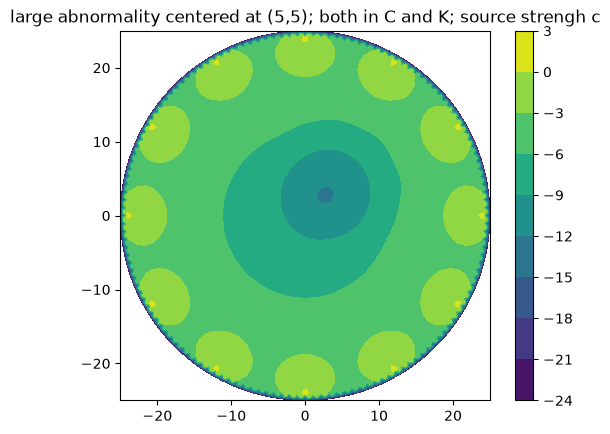

In [5]:
def absorption_large_abnormality(x, y):
    r = 25
    variation_r = 10
    if (x-5)**2 + (y-5)**2 < variation_r**2:
        absorption = 0.05
    elif x**2 + y**2 < r**2:
        absorption = 0.025
    else:
        absorption = 0.0
    return absorption * mr.c


def scattering_large_abnormality(x, y):
    r = 25
    variation_r = 10
    if (x-5)**2 + (y-5)**2 < variation_r**2:
        scattering = 4.0
    elif x**2 + y**2 < r**2:
        scattering = 2.0
    else:
        scattering = 0.0
    return scattering


def diffusion_large_abnormality(x, y):
    absorption = absorption_large_abnormality(x, y) / mr.c # remove the scaling by c
    scattering = scattering_large_abnormality(x, y)
    if absorption == 0.0 and scattering == 0.0: # i.e. we're outside region of interest
        diffusion = 0.0
    else:
        diffusion = mr.c / (3 * (absorption + scattering)) # assuming \bar{f} = 0
    return diffusion


mesh = CircularMesh(25, (0,0), 25)
sources = generate_equidistant_sources(radius=mesh.radius - 0.75*(mesh.radius / mesh.n_rings),
                                       n = 12,
                                       values=np.repeat(mr.c, 12))
Phi = optical_tomography_forward(mesh=mesh,
                                 absorption=absorption_large_abnormality,
                                 diffusion=diffusion_large_abnormality,
                                 sources=sources)
mr.plot_function_on_R(absorption_large_abnormality, -40, 40, -40, 40, "images/test_phi/large_abnormality/absorption_region.png")
mr.plot_function_on_R(diffusion_large_abnormality, -40, 40, -40, 40, "images/test_phi/large_abnormality/diffusion_region.png")
plot_function_on_mesh(mesh=mesh,
                      z=Phi,
                      savefile="images/test_phi/large_abnormality/phi.png",
                      title="large abnormality centered at (5,5); both in C and K; source strengh c",
                      log_scale=True)

### Single Source Animation

In [2]:
print("starting")
mesh = CircularMesh(25, (0,0), 25)
n_sources = 6*(mesh.n_rings-1)
source_coords, _ = generate_equidistant_sources(radius=mesh.radius - 0.75*(mesh.radius / mesh.n_rings),
                                                n = n_sources,
                                                values=None)
sources = [(source_coords, mr.c * one_hot) for one_hot in np.eye(n_sources)]
print("starting inversion")
Phis = optical_tomography_forward(mesh=mesh,
                                  absorption=mr.get_absorption,
                                  diffusion=mr.get_diffusion,
                                  sources=sources)
print("inversion complete")



starting
starting inversion
inverting...
calculating Phi 0
calculating Phi 1
calculating Phi 2
calculating Phi 3
calculating Phi 4
calculating Phi 5
calculating Phi 6
calculating Phi 7
calculating Phi 8
calculating Phi 9
calculating Phi 10
calculating Phi 11
calculating Phi 12
calculating Phi 13
calculating Phi 14
calculating Phi 15
calculating Phi 16
calculating Phi 17
calculating Phi 18
calculating Phi 19
calculating Phi 20
calculating Phi 21
calculating Phi 22
calculating Phi 23
calculating Phi 24
calculating Phi 25
calculating Phi 26
calculating Phi 27
calculating Phi 28
calculating Phi 29
calculating Phi 30
calculating Phi 31
calculating Phi 32
calculating Phi 33
calculating Phi 34
calculating Phi 35
calculating Phi 36
calculating Phi 37
calculating Phi 38
calculating Phi 39
calculating Phi 40
calculating Phi 41
calculating Phi 42
calculating Phi 43
calculating Phi 44
calculating Phi 45
calculating Phi 46
calculating Phi 47
calculating Phi 48
calculating Phi 49
calculating Phi 50


MovieWriter ffmpeg unavailable; using Pillow instead.


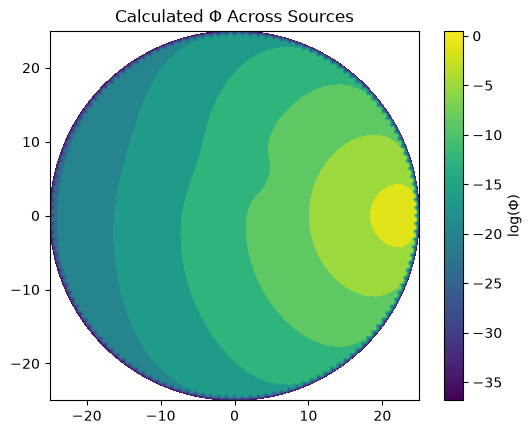

In [8]:
tri = Triangulation(x=mesh.coords[:, 0], y=mesh.coords[:, 1], triangles=mesh.triangles)
log_Phis = np.log(np.asarray(Phis) + 1e-16)
levels = np.linspace(log_Phis.min(), log_Phis.max(), 11)
norm = Normalize(vmin=levels[0], vmax=levels[-1])
cmap = "viridis"

fig, ax = plt.subplots()
fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), ax=ax, label=r"$\log(\Phi)$")

def animation(frame):
    ax.cla()
    ax.tricontourf(tri, log_Phis[frame], levels=levels, cmap=cmap, norm=norm)
    ax.set_aspect("equal")
    ax.set_title(r"Calculated $\Phi$ Across Sources")
    return ax.collections

anim = FuncAnimation(fig=fig, func=animation, frames=len(Phis), repeat=True)
anim.save("images/test_phi/animation/animation.gif", fps=12)

### No Scattering

This appears a bit confusion, but perhaps not if we consider the source as emitting photons in all directions equally.

inverting...
calculating Phi 0


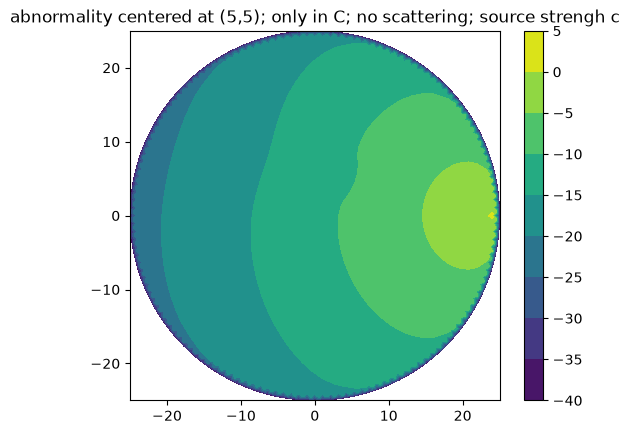

In [ ]:
def scattering_scatterless(x, y):
    return 0.0

def diffusion_scatterless(x, y):
    absorption = mr.get_absorption(x, y) / mr.c # remove the scaling by c
    scattering = scattering_scatterless(x, y)
    if absorption == 0.0 and scattering == 0.0: # i.e. we're outside region of interest
        diffusion = 0.0
    else:
        diffusion = mr.c / (3 * (absorption + scattering)) # assuming \bar{f} = 0
    return diffusion

mesh = CircularMesh(25, (0,0), 25)
values = np.repeat(0, 12)
values[0] = mr.c
sources = generate_equidistant_sources(radius=mesh.radius - 0.75*(mesh.radius / mesh.n_rings),
                                       n = 12,
                                       values=values)
Phi = optical_tomography_forward(mesh=mesh,
                                 absorption=mr.get_absorption,
                                 diffusion=mr.get_diffusion,
                                 sources=sources)
mr.plot_function_on_R(mr.get_absorption, -40, 40, -40, 40, "images/test_phi/scatterless/absorption_region.png")
mr.plot_function_on_R(diffusion_scatterless, -40, 40, -40, 40, "images/test_phi/scatterless/diffusion_region.png")
plot_function_on_mesh(mesh=mesh,
                      z=Phi,
                      savefile="images/test_phi/scatterless/phi.png",
                      title="abnormality centered at (5,5); only in C; no scattering; source strengh c",
                      log_scale=True)